In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

In [6]:
# calculating the efficient frontier
assets = ['AAPL','MSFT']
data = yf.download(assets,start='2010-01-01', auto_adjust=True)
data = data['Close']

c:\Users\vince\Portfolio_project\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\vince\Portfolio_project\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\vince\Portfolio_project\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.sort_

In [26]:
assets_return = data / data.iloc[0] * 100
assets_return

apple_multiple = assets_return['AAPL']['2026-11-17'] / assets_return['AAPL']['2010-01-04']
microsoft_multiple = assets_return['MSFT']['2026-11-17'] / assets_return['MSFT']['2010-01-04']
print(f"AAPL has a {round(apple_multiple,3)}x and MSFT has a {round(microsoft_multiple,3)}x")

AAPL has a 55.019x and MSFT has a 22.026x


<Axes: xlabel='Date'>

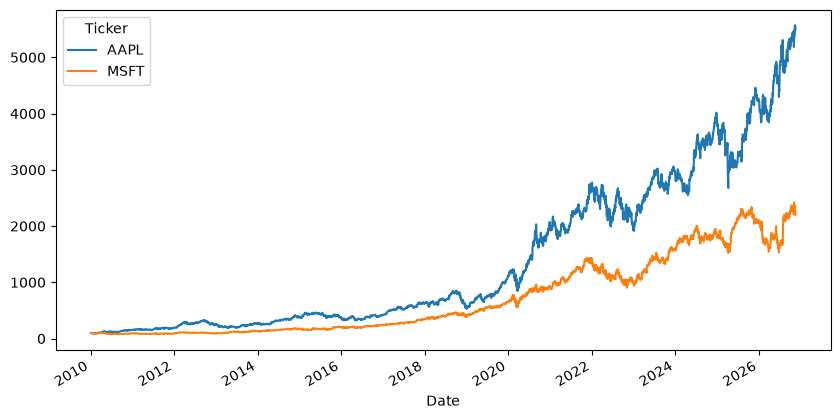

In [13]:
(assets_return).plot(figsize=(10,5))
#returns of apple and microsoft if you invested 100 dollars
#from 2010-01-01 to present day

In [ ]:
#we need the log return (in general, it is whats used in the equations)

log_returns = np.log(data / data.shift(1))
log_returns.mean() * 250 #annualized log return

Ticker
AAPL    0.236080
MSFT    0.182151
dtype: float64

In [28]:
log_returns.cov() * 250

Ticker,AAPL,MSFT
Ticker,,
AAPL,0.078087,0.040022
MSFT,0.040022,0.067417


In [ ]:
log_returns.corr() #fairly correlated (over 30% for sure)

Ticker,AAPL,MSFT
Ticker,,
AAPL,1.0000,0.5516
MSFT,0.5516,1.0000


In [31]:
num_assets = len(assets)
num_assets

2

In [42]:
#now need random weights
arr = np.random.random(2) #creates 2 random weights for us
arr

array([0.21925537, 0.04523013])

In [43]:
arr[0] + arr[1] 

np.float64(0.26448550370646406)

In [ ]:
#/= is the same as += or *= but for division
weights = np.random.random(num_assets)#2
weights /= np.sum(weights)
weights
#picks 2 random numbers, sums them up, and then divides each weight by the sum of the weights
#this fills an array with all the weights (whether it is 2 or 100 weights)


array([0.1262126, 0.8737874])

In [45]:
weights[0] + weights[1]

np.float64(1.0000000000000002)

In [ ]:
#expected return
np.sum(weights * log_returns.mean() * 250)
#expected annual return for this portfolio given these weights is 18.9%


np.float64(0.18895782576388168)

In [47]:
#expected portfolio variance
np.dot(weights.T,np.dot(log_returns.cov() * 250 ,weights))

np.float64(0.061544624128289455)

In [49]:
#std (volatality)
np.sqrt(np.dot(weights.T,np.dot(log_returns.cov() * 250 ,weights)))

np.float64(0.24808188996436129)

In [50]:
#creating a graph of 1000 mean variance simulations

In [ ]:
#need 2 empty lists
#1. for returns
#2. for volatility
port_returns = []
port_vol = []

for x in range (1000):
    weights = np.random.random(num_assets)
    weights /= np.sum(weights)
    port_returns.append(np.sum(weights * log_returns.mean() * 250))
    port_vol.append(np.sqrt(np.dot(weights.T,np.dot(log_returns.cov() * 250 ,weights))))

port_returns,port_vol

#looping through 1000 different times, we randomly generate 2 weights whose sum equals 1
#then we append each return into the return list and each vol into vol list (given the loops weights)


([np.float64(0.203966311192907),
  np.float64(0.20398917575647535),
  np.float64(0.20543874661259193),
  np.float64(0.21094207979974194),
  np.float64(0.20442290674678895),
  np.float64(0.22486034093993146),
  np.float64(0.2082164386634442),
  np.float64(0.21643041023055984),
  np.float64(0.2054384847092593),
  np.float64(0.22956809296442657),
  np.float64(0.2304940885776717),
  np.float64(0.18977556572973617),
  np.float64(0.20160058799902608),
  np.float64(0.21246590844407037),
  np.float64(0.2164403625397883),
  np.float64(0.21462259513673032),
  np.float64(0.20884767182296818),
  np.float64(0.22422201152909288),
  np.float64(0.2150021919075767),
  np.float64(0.19983925109743272),
  np.float64(0.1960985415720637),
  np.float64(0.19872599018529144),
  np.float64(0.19610828290336654),
  np.float64(0.20120299098773514),
  np.float64(0.21860734729048842),
  np.float64(0.21117575127156232),
  np.float64(0.23128785402175234),
  np.float64(0.2135877371289311),
  np.float64(0.21385643761656

In [54]:
#these are hard to read so we need a way to put them into an array
port_returns = np.array(port_returns)
port_vol = np.array(port_vol)

port_returns,port_vol #each array has the return that has a corresponding vol in the other array

(array([0.20396631, 0.20398918, 0.20543875, 0.21094208, 0.20442291,
        0.22486034, 0.20821644, 0.21643041, 0.20543848, 0.22956809,
        0.23049409, 0.18977557, 0.20160059, 0.21246591, 0.21644036,
        0.2146226 , 0.20884767, 0.22422201, 0.21500219, 0.19983925,
        0.19609854, 0.19872599, 0.19610828, 0.20120299, 0.21860735,
        0.21117575, 0.23128785, 0.21358774, 0.21385644, 0.20631779,
        0.21369601, 0.20579013, 0.22629245, 0.2128973 , 0.19032932,
        0.22256952, 0.20880471, 0.21109662, 0.1980273 , 0.20707012,
        0.18894692, 0.20298821, 0.19795432, 0.20752499, 0.21064185,
        0.20283641, 0.18994344, 0.20538589, 0.22685008, 0.23001185,
        0.21110071, 0.23246143, 0.22003075, 0.20061315, 0.18939192,
        0.20376479, 0.21095848, 0.20885555, 0.20502148, 0.23294401,
        0.21142282, 0.20778775, 0.18829151, 0.22450493, 0.20800059,
        0.22292512, 0.22516799, 0.19131697, 0.20247002, 0.20375848,
        0.21819577, 0.23077525, 0.20104811, 0.19

In [ ]:
portfolio = pd.DataFrame({'Return':port_returns, 'Volatility':port_vol})
portfolio.head() #first 5 pairs of return and volatility

,Return,Volatility
0,0.203966,0.236570
1,0.203989,0.236568
2,0.205439,0.236567
3,0.210942,0.238377
4,0.204423,0.236547


Text(0, 0.5, 'Expected Return')

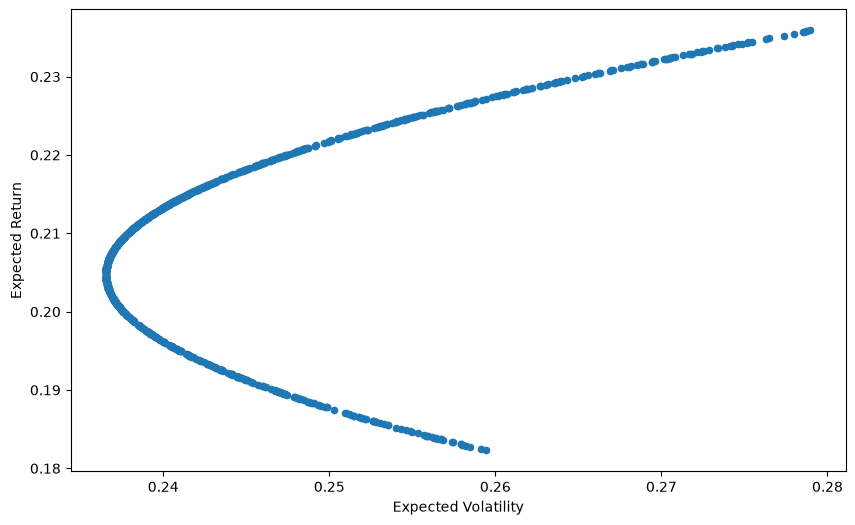

In [ ]:
#now to plot
portfolio.plot(x='Volatility', y='Return', kind='scatter',figsize=(10,6))
#kind allows us to plot the type of plot we want
#plots a perfect markowitz curve
plt.xlabel('Expected Volatility')
plt.ylabel('Expected Return')


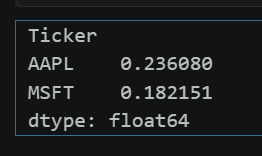

We can see here that Apple's 100% (Asset A) is the top right tip

Whereas Microsfofts 100% (Asset B) is the very bottom (to middle right ish) tip

In [ ]:
#minimum variance portfolio
min_var_idx = portfolio['Volatility'].idxmin()
#idxmin() gives us the location of the lowest value
min_var_port = portfolio.loc[min_var_idx]
min_var_port

Return        0.204719
Volatility    0.236542
Name: 609, dtype: float64

In [67]:
print(f"The Minimum Variance Portfolio is a volatility of {round(min_var_port['Volatility'],4) * 100}% with a expected annual return of {round(min_var_port['Return'],4) * 100}%")

The Minimum Variance Portfolio is a volatility of 23.65% with a expected annual return of 20.47%


In [68]:
#questions going forward to work on
#sharpe ratio? (Max sharpe)
#Optimal portfolio?
#Frontier?